# Análisis de sentimiento (fase 5)

Notebook de la fase 5. Esta versión tiene la sección **Etiquetado**: arma la muestra de notas (`PER_MEDIO` por medio), exporta las dos planillas para los anotadores y valida las etiquetas devueltas. Las secciones de evaluación y de evolución se agregan en commits siguientes.

## 1. Etiquetado

> **Importante.** La muestra se saca **solo** del dataset completo y congelado que comparte el equipo (con los tres medios: MisionesOnline, Infobae y La Nación). La muestra depende de los `id` presentes: si se saca de un `data/noticias_politica.parquet` incompleto, queda distinta. La celda de abajo falla con un mensaje claro si algún medio tiene menos notas elegibles que `PER_MEDIO`.
>
> Este notebook se commitea **con salidas** (métricas, tablas y gráficos; ninguna muestra texto de las notas). Las planillas contienen texto scrapeado y quedan en `data/etiquetado/` (ignorado por git); solo se commitea `anotaciones/etiquetas.csv` (`id, anotador, etiqueta`, sin texto). La guía para los anotadores está en `docs/guia-etiquetado.md`.

In [1]:
from pathlib import Path

import pandas as pd

from news_politica.sentiment.labeling import (
    ANOTADORES,
    SAMPLE_SALT,
    export_sheets,
    labeling_sample,
    read_labels,
)

DATA = Path("../data")
ANOTACIONES = Path("../anotaciones")
PER_MEDIO = 100

notes = pd.read_parquet(DATA / "noticias_politica.parquet")
print(len(notes), "notas;", "semilla:", SAMPLE_SALT)
notes["medio"].value_counts()

9261 notas; semilla: etiquetado-2026-10


medio
misionesonline    7245
lanacion          1020
infobae            996
Name: count, dtype: int64

### Muestra y exportación

`labeling_sample` filtra notas en vivo y títulos vacíos, ordena por `sha1(semilla + id)` dentro de cada medio y toma `PER_MEDIO`. Los anotadores `a` y `b` se alternan, así que cada uno recibe la mitad de cada medio, sin notas en común. `export_sheets` escribe `anotador_a.csv` y `anotador_b.csv` con `id, texto, etiqueta` y sin medio ni salida de modelos.

In [2]:
sample = labeling_sample(notes, per_medio=PER_MEDIO)
try:
    paths = export_sheets(sample, DATA / "etiquetado")  # never overwrites filled sheets
    print("planillas escritas:", [p.name for p in paths])
except FileExistsError as exc:
    print("No se escribió nada:", exc)
print(sample.groupby(["medio", "anotador"]).size().unstack())
a_ids = set(sample.loc[sample["anotador"] == "a", "id"])
b_ids = set(sample.loc[sample["anotador"] == "b", "id"])
print("ids compartidos:", len(a_ids & b_ids))
print(sample["fuente_texto"].value_counts())

No se escribió nada: ['anotador_a.csv', 'anotador_b.csv'] already exist in ../data/etiquetado; they may hold filled labels. Pass overwrite=True only if you really want to replace them.
anotador         a   b
medio                 
infobae         50  50
lanacion        50  50
misionesonline  50  50
ids compartidos: 0
fuente_texto
bajada    274
cuerpo     26
Name: count, dtype: int64


### Unión de etiquetas

Cuando los dos integrantes devuelvan sus archivos completos a `data/etiquetado/`, esta celda los valida con `read_labels` (etiquetas dentro de `pos`, `neu`, `neg`, `descartar`; ids de la muestra; sin repetidos ni vacíos) y escribe `anotaciones/etiquetas.csv` con `id, anotador, etiqueta`.

La celda no depende de la exportación: arma la muestra (determinística) y toma los archivos de `data/etiquetado/` por su nombre. La exportación nunca pisa planillas que ya existen; para regenerarlas hay que pasar `overwrite=True` a propósito.

In [3]:
sample = labeling_sample(notes, per_medio=PER_MEDIO)
sheet_paths = [DATA / "etiquetado" / f"anotador_{a}.csv" for a in ANOTADORES]
labels = read_labels(sheet_paths, sample)
ANOTACIONES.mkdir(exist_ok=True)
labels.to_csv(ANOTACIONES / "etiquetas.csv", index=False)
print(len(labels), "etiquetas")
labels["etiqueta"].value_counts()

300 etiquetas


etiqueta
neg    134
neu    121
pos     45
Name: count, dtype: int64

## 2. Evaluación

Compara cada modelo con las etiquetas de las notas de la muestra. Las puntuaciones **no se recalculan** acá: se leen del asset guardado `data/sentimiento_noticias.parquet` (todos los modelos que contiene) y se filtran a las notas de la muestra. Así la evaluación es reproducible, no necesita GPU ni Ollama y cubre los tres modelos.

- Las etiquetas están en `anotaciones/etiquetas.csv` (celda de unión de la sección 1). Se leen con `load_labels`, que valida las mismas reglas que `read_labels` contra la muestra.
- Las etiquetas las generó un modelo (Claude Opus 5.5), no personas: las métricas miden **concordancia con esas etiquetas**, no con una lectura humana (ver `docs/decision-sentimiento.md`).

`evaluate` excluye las notas marcadas `descartar` y calcula exactitud, F1 macro y F1 por clase. Una salida del modelo que no se pudo interpretar cuenta como error y aparece en la matriz de confusión como `sin_respuesta`.

### Puntajes guardados de la muestra

In [4]:
from news_politica.sentiment.evaluation import evaluate
from news_politica.sentiment.labeling import load_labels

muestra = labeling_sample(notes, per_medio=PER_MEDIO)
etiquetas = load_labels(ANOTACIONES / "etiquetas.csv", muestra)  # same checks as read_labels
guardados = pd.read_parquet(DATA / "sentimiento_noticias.parquet")
scores = guardados.merge(muestra[["id", "medio"]], on="id")  # only the sample notes, plus the outlet
print(len(muestra), "notas en la muestra;", len(etiquetas), "etiquetas")
print(scores.groupby("modelo")["label"].value_counts(dropna=False))

300 notas en la muestra; 300 etiquetas
modelo         label
mdeberta-xnli  neg      124
               pos      101
               neu       75
qwen2.5-7b     neu      243
               neg       36
               pos       21
robertuito     neu      151
               neg      117
               pos       32
Name: count, dtype: int64


### Métricas por modelo

Total, por medio y según el texto de análisis (`bajada`, `cuerpo` o `titulo`).

In [5]:
por_modelo, confusion_modelo = evaluate(etiquetas, scores, by=("modelo",))
por_medio, _ = evaluate(etiquetas, scores, by=("modelo", "medio"))
por_fuente, _ = evaluate(etiquetas, scores, by=("modelo", "fuente_texto"))
for titulo, tabla in (("Por modelo", por_modelo), ("Por modelo y medio", por_medio), ("Por modelo y fuente de texto", por_fuente)):
    print(titulo)
    display(tabla.round(3))

Por modelo


,modelo,n,accuracy,macro_f1,f1_pos,f1_neu,f1_neg
0,mdeberta-xnli,300,0.603,0.579,0.493,0.500,0.744
1,qwen2.5-7b,300,0.580,0.549,0.576,0.659,0.412
2,robertuito,300,0.703,0.686,0.623,0.676,0.757


Por modelo y medio


,modelo,medio,n,accuracy,macro_f1,f1_pos,f1_neu,f1_neg
0,mdeberta-xnli,infobae,100,0.58,0.541,0.390,0.522,0.711
1,mdeberta-xnli,lanacion,100,0.68,0.614,0.467,0.596,0.779
2,mdeberta-xnli,misionesonline,100,0.55,0.562,0.560,0.400,0.727
3,qwen2.5-7b,infobae,100,0.60,0.527,0.500,0.702,0.377
4,qwen2.5-7b,lanacion,100,0.49,0.532,0.667,0.541,0.390
5,qwen2.5-7b,misionesonline,100,0.65,0.600,0.579,0.721,0.500
6,robertuito,infobae,100,0.79,0.776,0.737,0.787,0.805
7,robertuito,lanacion,100,0.64,0.618,0.615,0.514,0.726
8,robertuito,misionesonline,100,0.68,0.672,0.578,0.692,0.745


Por modelo y fuente de texto


,modelo,fuente_texto,n,accuracy,macro_f1,f1_pos,f1_neu,f1_neg
0,mdeberta-xnli,bajada,274,0.602,0.575,0.481,0.503,0.742
1,mdeberta-xnli,cuerpo,26,0.615,0.612,0.588,0.471,0.778
2,qwen2.5-7b,bajada,274,0.573,0.543,0.586,0.657,0.387
3,qwen2.5-7b,cuerpo,26,0.654,0.619,0.500,0.690,0.667
4,robertuito,bajada,274,0.719,0.697,0.625,0.694,0.771
5,robertuito,cuerpo,26,0.538,0.550,0.615,0.500,0.533


### Matrices de confusión

Filas: etiqueta. Columnas: predicción del modelo.

In [6]:
for modelo, tabla in confusion_modelo.groupby("modelo"):
    print(modelo)
    display(tabla.pivot(index="etiqueta", columns="prediccion", values="n"))

mdeberta-xnli


prediccion,neg,neu,pos,sin_respuesta
etiqueta,,,,
neg,96,20,18,0
neu,25,49,47,0
pos,3,6,36,0


qwen2.5-7b


prediccion,neg,neu,pos,sin_respuesta
etiqueta,,,,
neg,35,97,2,0
neu,1,120,0,0
pos,0,26,19,0


robertuito


prediccion,neg,neu,pos,sin_respuesta
etiqueta,,,,
neg,95,39,0,0
neu,21,92,8,0
pos,1,20,24,0


## 3. Evolución del tono

Serie semanal del puntaje medio (`prob_pos - prob_neg`) por medio, para el modelo elegido (`MODELO_FINAL`), con el intervalo t del 95 % de cada semana y una media móvil de 4 semanas. Las líneas verticales marcan los hitos de `anotaciones/hitos.csv` que tienen fecha. Debajo, `prop_bajada` muestra qué parte de las notas de cada semana se analizó con bajada (la bajada cambia el texto de análisis y puede mover el puntaje).

> **Fechas de los hitos.** Verificadas contra la fuente de `anotaciones/hitos.csv`. El DNU 70/2023 usa el día del anuncio (20/12/2023), no el de publicación, y la Ley Bases la aprobación en general del Senado (12/06/2024).
>
> **Muestreo de Infobae y La Nación.** Sus catálogos leen solo los sitemaps de los días 5 y 20 de cada mes, así que cada semana con datos refleja un solo día y hay semanas vacías (ver `docs/decision-sentimiento.md`). La serie de esos medios no es continua; MisionesOnline sí lo es.

robertuito - semanas por medio:
medio
infobae            77
lanacion          147
misionesonline    148
dtype: int64


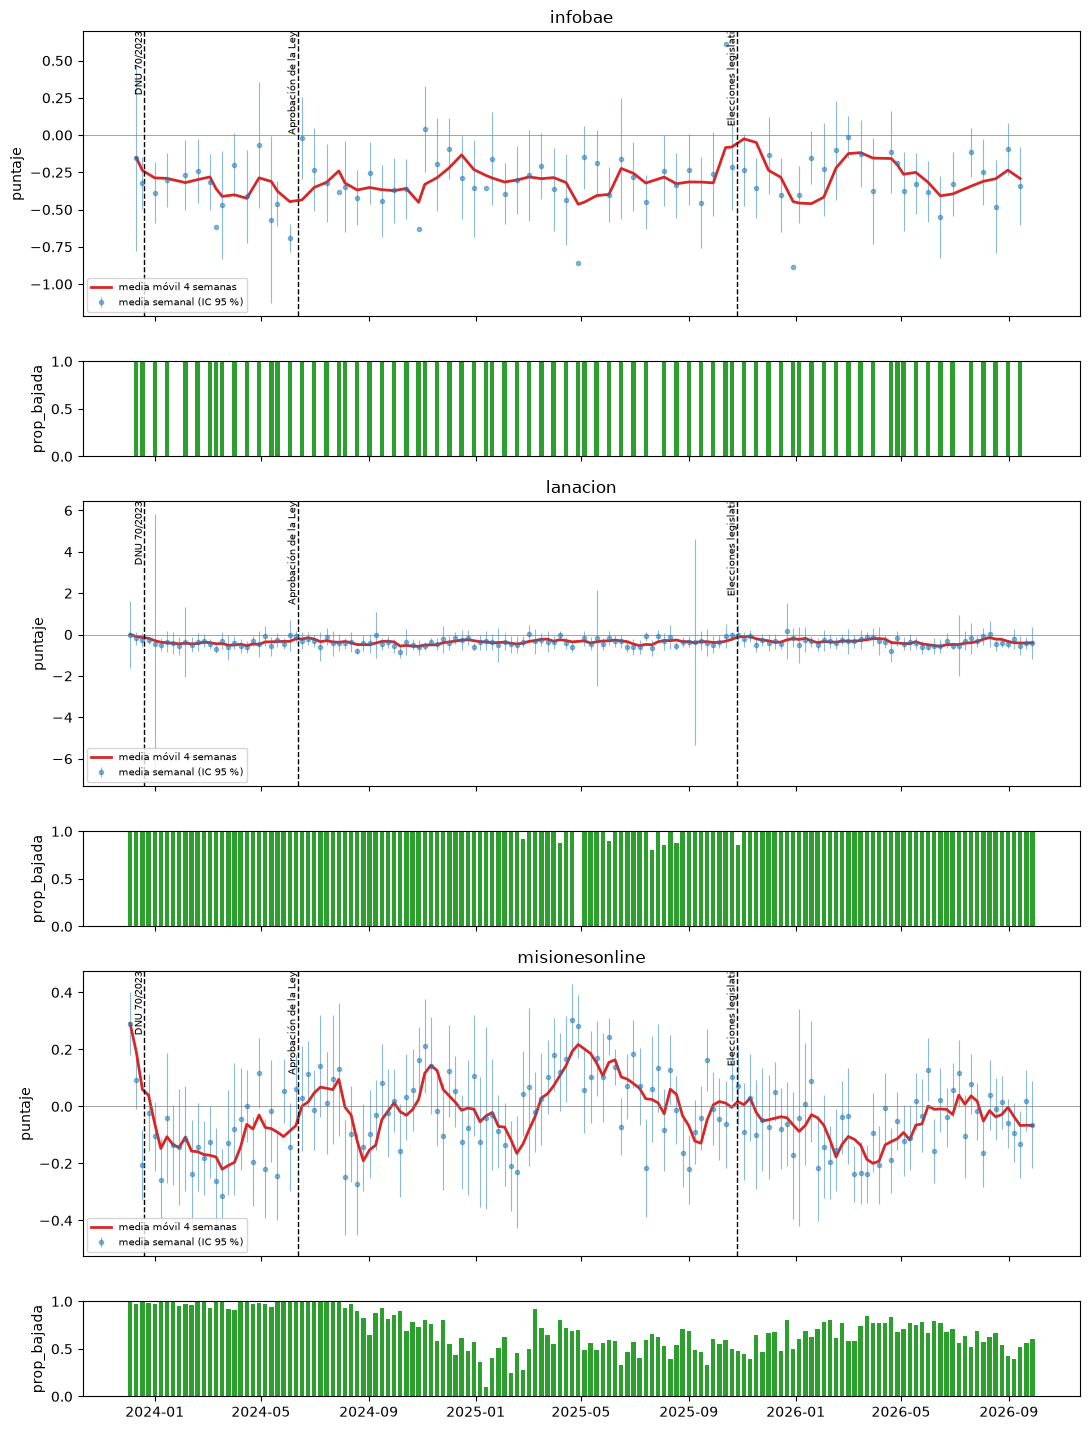

In [7]:
import matplotlib.pyplot as plt

from news_politica.defs.sentiment import MODELO_FINAL

semanal = pd.read_parquet(DATA / "evolucion_tono.parquet")
hitos = pd.read_csv(ANOTACIONES / "hitos.csv")
fechas_hitos = hitos.dropna(subset=["fecha"])
final = semanal[semanal["modelo"] == MODELO_FINAL]
print(MODELO_FINAL, "- semanas por medio:")
print(final.groupby("medio").size())

medios = sorted(final["medio"].unique())
fig, ejes = plt.subplots(2 * len(medios), 1, figsize=(11, 3.2 * len(medios) * 1.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1] * len(medios)})
for i, medio in enumerate(medios):
    d = final[final["medio"] == medio].sort_values("semana")
    x = d["semana"].dt.tz_localize(None)
    ax, ax_cob = ejes[2 * i], ejes[2 * i + 1]
    ax.errorbar(x, d["score_medio"], yerr=[d["score_medio"] - d["ic_inf"], d["ic_sup"] - d["score_medio"]],
                fmt="o", ms=3, lw=0.8, alpha=0.5, label="media semanal (IC 95 %)")
    ax.plot(x, d["score_medio"].rolling(4, min_periods=1).mean(), color="C3", lw=2, label="media móvil 4 semanas")
    ax.axhline(0, color="grey", lw=0.5)
    for h in fechas_hitos.itertuples():
        if h.alcance == "nacional" or h.alcance == "misiones" and medio == "misionesonline":
            ax.axvline(pd.Timestamp(h.fecha), color="k", ls="--", lw=1)
            ax.text(pd.Timestamp(h.fecha), ax.get_ylim()[1], h.hito[:20], rotation=90, va="top", ha="right", fontsize=7)
    ax.set_title(medio)
    ax.set_ylabel("puntaje")
    ax.legend(loc="lower left", fontsize=7)
    ax_cob.bar(x, d["prop_bajada"], width=5, color="C2")
    ax_cob.set_ylabel("prop_bajada")
    ax_cob.set_ylim(0, 1)
plt.tight_layout()
plt.show()

## 4. Hitos

Compara el puntaje medio de las dos semanas anteriores y las dos posteriores a cada hito (`compare_milestones`, ventanas de 14 días; el día del hito cuenta como "después"). Los hitos son nacionales y se comparan en los tres medios. Se marcan las ventanas **truncadas** (el período del dataset cortó la ventana) e **insuficientes** (menos de `N_MIN` notas en un lado: no se informa media ni proporción). Los hitos sin fecha se omiten.

In [8]:
from news_politica.sentiment.tone import compare_milestones

comparacion = compare_milestones(guardados[guardados["modelo"] == MODELO_FINAL], notes, hitos)
comparacion = comparacion[(comparacion["alcance"] == "nacional") | (comparacion["medio"] == "misionesonline")]
comparacion["aviso"] = comparacion.apply(
    lambda r: ", ".join(x for x, f in (("truncada", r["truncada"]), ("insuficiente", r["insuficiente"])) if f), axis=1)
display(comparacion[["hito", "fecha", "medio", "n_antes", "n_despues", "score_antes", "score_despues",
                     "diferencia", "ic_inf", "ic_sup", "prop_neg_antes", "prop_neg_despues",
                     "dias_antes", "dias_despues", "aviso"]].round(3))

,hito,fecha,medio,n_antes,n_despues,score_antes,score_despues,diferencia,ic_inf,ic_sup,prop_neg_antes,prop_neg_despues,dias_antes,dias_despues,aviso
0,DNU 70/2023,2023-12-20,infobae,9,21,NaN,-0.371,NaN,NaN,NaN,NaN,0.429,10,14,"truncada, insuficiente"
1,DNU 70/2023,2023-12-20,lanacion,13,18,-0.127,-0.337,-0.210,-0.493,0.073,0.231,0.333,10,14,truncada
2,DNU 70/2023,2023-12-20,misionesonline,128,94,0.116,-0.112,-0.228,-0.345,-0.110,0.125,0.245,10,14,truncada
3,Aprobación de la Ley Bases en el Senado (junio...,2024-06-12,infobae,16,12,-0.691,-0.020,0.671,0.387,0.954,0.812,0.167,14,14,
4,Aprobación de la Ley Bases en el Senado (junio...,2024-06-12,lanacion,12,16,-0.271,-0.205,0.066,-0.295,0.428,0.500,0.188,14,14,
5,Aprobación de la Ley Bases en el Senado (junio...,2024-06-12,misionesonline,87,73,-0.011,0.056,0.067,-0.071,0.205,0.207,0.178,14,14,
6,Elecciones legislativas 2025,2025-10-26,infobae,16,16,-0.163,-0.235,-0.072,-0.436,0.292,0.312,0.438,14,14,
7,Elecciones legislativas 2025,2025-10-26,lanacion,11,20,-0.090,-0.120,-0.029,-0.330,0.271,0.273,0.300,14,14,
8,Elecciones legislativas 2025,2025-10-26,misionesonline,97,136,-0.047,0.115,0.162,0.040,0.284,0.227,0.154,14,14,
